# Atropelamentos em São Paulo (2022–2025): entorno dos pontos críticos (escolas e semáforos)

**Pré-requisito:** rodar antes o notebook `03_dbscan_pontos_criticos.ipynb`, que cria o banco
`data/processed/seguranca_viaria.db` com a tabela `clusters`.

**Pergunta:** o que existe em volta de cada concentração de atropelamentos?

1. há **escola** perto? Isso justifica o modo **"escola"** do nó, que muda o semáforo e a sinalização nos
   horários de entrada e saída;
2. há **semáforo** e **travessia semaforizada**? Um ponto crítico sem semáforo é candidato ao modo
   **"pedestre"** (travessia acionada e aviso ao motorista), e um ponto com semáforo pode receber ajuste de
   tempo de travessia;
3. com isso, **o Largo da Concórdia se confirma como piloto?**

Este é o passo 4 do método (enriquecer os grupos com o entorno urbano) e responde ao item "O que ainda falta
confirmar" do planejamento.

## 1. Configuração

In [1]:
from pathlib import Path
import json, sqlite3, unicodedata, urllib.request, urllib.parse, datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
from sklearn.neighbors import BallTree

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
RAW_GEO = ROOT / "data" / "raw" / "geosampa"
RAW_OSM = ROOT / "data" / "raw" / "osm"
for p in (RAW_GEO, RAW_OSM):
    p.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data" / "processed"
EVID = ROOT / "docs" / "evidencias" / "estudo_b"
DB_PATH = PROCESSED / "seguranca_viaria.db"
R_TERRA = 6_371_000
HOJE = dt.date.today().isoformat()

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

def salvar(fig, nome):
    fig.savefig(EVID / nome, dpi=150, bbox_inches="tight", facecolor="white")

def sem_acento(x):
    return unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode() if isinstance(x, str) else x

## 2. Fontes

| Tema | Fonte | Papel | Arquivo em `data/raw/` |
|---|---|---|---|
| Semáforos e travessias semaforizadas | **OpenStreetMap**, via Overpass API, município de São Paulo (`admin_level=8`) | **fonte principal** | `osm/semaforos_osm_sp_AAAA-MM-DD.geojson` |
| Semáforos | **GeoSampa**, cadastro da CET (carga de **2018**) | **base de comparação** | `geosampa/geosampa_semaforo_2018_baixado_AAAA-MM-DD.geojson` |
| Escolas públicas | **GeoSampa**, camadas de equipamentos de educação | **fonte principal** (oficial) | `geosampa/geosampa_equipamento_educacao_*_AAAA-MM-DD.geojson` |
| Escolas | **OpenStreetMap**, `amenity=school` (nós e áreas, centro das áreas) | **conferência** | `osm/escolas_osm_sp_AAAA-MM-DD.geojson` |

> **Ressalva sobre as fontes.**
> - **OpenStreetMap:** é **recente** (atualizado continuamente; a base usada aqui é a do dia do download), mas
>   **depende de voluntários**. A cobertura é desigual: bairros mapeados com cuidado convivem com bairros
>   onde faltam semáforos. A data de cada nó (`out meta`) é a da **última edição** do ponto, e não a de uma
>   vistoria. Por outro lado, o OSM distingue **semáforo veicular** (`highway=traffic_signals`) de **travessia
>   de pedestre semaforizada** (`crossing=traffic_signals` ou `crossing:signals=yes`), algo que o cadastro
>   oficial não faz.
> - **GeoSampa (semáforos):** é **oficial** (cadastro da CET), mas a carga é de **2018**: o que foi instalado ou
>   retirado depois não aparece. Ele também **não diz se há foco para pedestre**. Por isso deixou de ser a
>   fonte principal e virou comparação.
> - **Escolas:** o **Catálogo de Escolas do INEP** (Censo Escolar) foi tentado **duas vezes**. Na primeira, a
>   página do INEP só tinha o link para um portal analítico interativo, sem arquivo para baixar. Na segunda, o
>   **portal derrubou a conexão**. A fonte usada foi o **GeoSampa** (oficial), com **data de atualização: data
>   não informada pela fonte**. As camadas não trazem campo de data, e a ficha delas não apareceu no catálogo
>   de metadados (`metadados.geosampa.prefeitura.sp.gov.br`) na única tentativa feita. A ficha que apareceu
>   foi a da camada vizinha "Outros - Educação", atualizada em 24/06/2025: é um indício de atualização
>   recente, mas não vale para as camadas usadas. O **OpenStreetMap entrou como conferência** (seção 2.3):
>   ele não substitui a base oficial, só mostra o quanto as duas concordam.
>
> Nenhuma das bases responde se o semáforo tem **foco para pedestre** ou **contagem regressiva**, que é o que
> importa para o idoso. Isso fica para a verificação manual da seção 5.2.

**Download:** se um arquivo não existir em `data/raw/`, as células abaixo o baixam (WFS do GeoSampa e
Overpass do OSM). Assim `data/raw/` pode continuar fora do Git, pela regra do template, e o notebook continua
reproduzível. Quando há mais de uma data, usamos a mais recente.

In [2]:
# --- GeoSampa (WFS) ---
WFS = ("https://wfs.geosampa.prefeitura.sp.gov.br/geoserver/geoportal/wfs?service=WFS&version=2.0.0"
       "&request=GetFeature&typeNames=geoportal:{camada}&outputFormat=application/json&srsName=EPSG:4326")
CAMADAS_GEO = ["equipamento_educacao_rede_publica", "equipamento_educacao_infantil_rede_publica",
               "equipamento_educacao_ceu", "semaforo"]

def baixar(url: str, destino: Path, dados: bytes | None = None, timeout=300) -> Path:
    req = urllib.request.Request(url, data=dados, headers={"User-Agent": "GS-FIAP-estudo-b/1.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        destino.write_bytes(r.read())
    return destino

def camada_geosampa(camada: str) -> Path:
    existentes = sorted(RAW_GEO.glob(f"geosampa_{camada}_*.geojson"))
    if existentes:
        return existentes[-1]
    sufixo = "2018_baixado_" if camada == "semaforo" else ""  # a carga dos semáforos é de 2018
    return baixar(WFS.format(camada=camada), RAW_GEO / f"geosampa_{camada}_{sufixo}{HOJE}.geojson")

def ler_pontos(arq: Path) -> pd.DataFrame:
    fc = json.loads(arq.read_text(encoding="utf-8"))
    linhas = [{**f["properties"], "longitude": f["geometry"]["coordinates"][0], "latitude": f["geometry"]["coordinates"][1]}
              for f in fc["features"] if f.get("geometry") and f["geometry"]["type"] == "Point"]
    df = pd.DataFrame(linhas).assign(arquivo=arq.name)
    df.attrs.update(descartados=len(fc["features"]) - len(linhas), meta=fc.get("metadata", {}), crs=fc.get("crs"))
    return df

geo_brutos = {c: ler_pontos(camada_geosampa(c)) for c in CAMADAS_GEO}
for c, d in geo_brutos.items():
    assert "4326" in json.dumps(d.attrs["crs"]), f"{c}: esperado EPSG:4326"

# --- OpenStreetMap (Overpass) ---
OVERPASS = ["https://overpass-api.de/api/interpreter", "https://overpass.kumi.systems/api/interpreter"]
QUERY = """[out:json][timeout:600];
area["boundary"="administrative"]["admin_level"="8"]["wikidata"="Q174"]->.sp;
(
  node["highway"="traffic_signals"](area.sp);
  node["crossing"="traffic_signals"](area.sp);
  node["crossing:signals"="yes"](area.sp);
);
out meta;"""

def camada_osm() -> Path:
    existentes = sorted(RAW_OSM.glob("semaforos_osm_sp_*.geojson"))
    if existentes:
        return existentes[-1]
    for url in OVERPASS:  # tenta o servidor principal e, se falhar, o espelho (uma vez)
        try:
            bruto = RAW_OSM / "_overpass.json"
            baixar(url, bruto, urllib.parse.urlencode({"data": QUERY}).encode(), timeout=700)
            break
        except Exception as e:
            print("Overpass falhou em", url, "→", e)
    else:
        raise RuntimeError("Overpass indisponível nos dois servidores")
    d = json.loads(bruto.read_text(encoding="utf-8")); bruto.unlink()
    feats = [{"type": "Feature", "geometry": {"type": "Point", "coordinates": [el["lon"], el["lat"]]},
              "properties": {"osm_id": el["id"], "timestamp": el.get("timestamp"), "version": el.get("version"),
                             **{k.replace(":", "_"): el.get("tags", {}).get(k) for k in
                                ["highway", "crossing", "crossing:signals", "button_operated",
                                 "traffic_signals:sound", "traffic_signals:countdown"]}}}
             for el in d["elements"] if el.get("type") == "node"]
    arq = RAW_OSM / f"semaforos_osm_sp_{HOJE}.geojson"
    arq.write_text(json.dumps({"type": "FeatureCollection", "features": feats,
                               "metadata": {"fonte": "OpenStreetMap via Overpass API (ODbL)", "query": QUERY,
                                            "osm_base": d.get("osm3s", {}).get("timestamp_osm_base"),
                                            "baixado_em": HOJE}}, ensure_ascii=False), encoding="utf-8")
    return arq

QUERY_ESCOLAS = """[out:json][timeout:600];
area["boundary"="administrative"]["admin_level"="8"]["wikidata"="Q174"]->.sp;
nwr["amenity"="school"](area.sp);
out center meta;"""

def camada_osm_escolas() -> Path:
    existentes = sorted(RAW_OSM.glob("escolas_osm_sp_*.geojson"))
    if existentes:
        return existentes[-1]
    for url in OVERPASS:
        try:
            bruto = RAW_OSM / "_overpass_escolas.json"
            baixar(url, bruto, urllib.parse.urlencode({"data": QUERY_ESCOLAS}).encode(), timeout=700)
            break
        except Exception as e:
            print("Overpass falhou em", url, "→", e)
    else:
        raise RuntimeError("Overpass indisponível nos dois servidores")
    d = json.loads(bruto.read_text(encoding="utf-8")); bruto.unlink()
    feats = []
    for el in d["elements"]:
        pos = (el["lat"], el["lon"]) if el["type"] == "node" else (el["center"]["lat"], el["center"]["lon"]) if "center" in el else None
        if pos:
            t = el.get("tags", {})
            feats.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [pos[1], pos[0]]},
                          "properties": {"osm_type": el["type"], "osm_id": el["id"], "timestamp": el.get("timestamp"),
                                         "name": t.get("name"), "operator": t.get("operator"),
                                         "operator_type": t.get("operator:type"), "isced_level": t.get("isced:level"),
                                         "school_br": t.get("school:BR") or t.get("school")}})
    arq = RAW_OSM / f"escolas_osm_sp_{HOJE}.geojson"
    arq.write_text(json.dumps({"type": "FeatureCollection", "features": feats,
                               "metadata": {"fonte": "OpenStreetMap via Overpass API (ODbL)", "query": QUERY_ESCOLAS,
                                            "osm_base": d.get("osm3s", {}).get("timestamp_osm_base"),
                                            "baixado_em": HOJE}}, ensure_ascii=False), encoding="utf-8")
    return arq

osm = ler_pontos(camada_osm())
esc_osm = ler_pontos(camada_osm_escolas())
osm["e_semaforo"] = osm["highway"].fillna("").str.contains("traffic_signals")
osm["e_travessia"] = osm["crossing"].eq("traffic_signals") | osm["crossing_signals"].eq("yes")
osm["ultima_edicao"] = pd.to_datetime(osm["timestamp"])

pd.DataFrame({"arquivo": [d["arquivo"].iloc[0] for d in geo_brutos.values()] + [osm["arquivo"].iloc[0], esc_osm["arquivo"].iloc[0]],
              "pontos": [len(d) for d in geo_brutos.values()] + [len(osm), len(esc_osm)],
              "descartados (sem ponto)": [d.attrs["descartados"] for d in geo_brutos.values()]
                                         + [osm.attrs["descartados"], esc_osm.attrs["descartados"]]},
             index=[f"GeoSampa · {c}" for c in CAMADAS_GEO] + ["OSM · semáforos e travessias", "OSM · escolas (amenity=school)"])

,arquivo,pontos,descartados (sem ponto)
GeoSampa · equipamento_educacao_rede_publica,geosampa_equipamento_educacao_rede_publica_202...,1597,0
GeoSampa · equipamento_educacao_infantil_rede_publica,geosampa_equipamento_educacao_infantil_rede_pu...,3041,0
GeoSampa · equipamento_educacao_ceu,geosampa_equipamento_educacao_ceu_2026-11-11.g...,150,0
GeoSampa · semaforo,geosampa_semaforo_2018_baixado_2026-11-11.geojson,6419,13
OSM · semáforos e travessias,semaforos_osm_sp_2026-11-11.geojson,9885,0
OSM · escolas (amenity=school),escolas_osm_sp_2026-11-11.geojson,1614,0


In [3]:
print(f"OSM: base de {osm.attrs['meta'].get('osm_base')} | {len(osm):,} nós")
print(f"  semáforo veicular (highway=traffic_signals): {osm['e_semaforo'].sum():,}")
print(f"  travessia semaforizada (crossing=traffic_signals ou crossing:signals=yes): {osm['e_travessia'].sum():,}")
print(f"  as duas marcações no mesmo nó: {(osm['e_semaforo'] & osm['e_travessia']).sum():,}")
print(f"  última edição: mediana {osm['ultima_edicao'].median():%m/%Y} | "
      f"{(osm['ultima_edicao'].dt.year >= 2023).mean():.0%} editados de 2023 em diante | "
      f"{(osm['ultima_edicao'].dt.year <= 2018).mean():.0%} sem edição desde 2018 ou antes")
print("  marcações de acessibilidade (raras):",
      {c: osm[c].value_counts().to_dict() for c in ["button_operated", "traffic_signals_sound", "traffic_signals_countdown"]})

OSM: base de 2026-11-12T01:42:29Z | 9,885 nós
  semáforo veicular (highway=traffic_signals): 6,849
  travessia semaforizada (crossing=traffic_signals ou crossing:signals=yes): 3,422
  as duas marcações no mesmo nó: 386
  última edição: mediana 04/2021 | 28% editados de 2023 em diante | 19% sem edição desde 2018 ou antes
  marcações de acessibilidade (raras): {'button_operated': {'no': 148, 'yes': 143, 'only': 1}, 'traffic_signals_sound': {'no': 362, 'yes': 17}, 'traffic_signals_countdown': {'yes': 2}}


### 2.1 O que conta como "escola" e como "semáforo"

**Escolas.** Para o modo escola, interessa o lugar onde há **entrada e saída concentrada de crianças e
adolescentes a pé, em horário fixo**. Entram:

- **EE, EMEF e EMEFM** (ensino fundamental e médio, estaduais e municipais): alunos que atravessam sozinhos;
- **EMEI e CEMEI** (pré-escola municipal): crianças pequenas com acompanhante, em horário fixo;
- **unidades dos CEUs** (EMEF, EMEI e CEI do CEU).

**Ficam fora as creches** (CEI direto ou indireto e creches particulares conveniadas, ~2,5 mil pontos). Elas
atendem crianças de 0 a 3 anos, que chegam no colo ou de carrinho, em horários espalhados. Contá-las
inflaria o indicador sem relação com a travessia escolar. **Unidades no mesmo endereço** (CEU com EMEF + EMEI
+ CEI, escola estadual e municipal no mesmo prédio) contam como **um local**: arredondamos a coordenada a
~10 m e juntamos os nomes.

**Semáforos.**
- **OSM (principal):** `e_semaforo` = `highway=traffic_signals`; `e_travessia` = `crossing=traffic_signals` ou
  `crossing:signals=yes`. Um nó pode ter as duas marcações. **Atenção:** no OSM um cruzamento semaforizado
  costuma ter **vários nós** (um por aproximação ou faixa), então as contagens do OSM medem **nós**, não
  cruzamentos. Para "tem ou não tem", isso não importa; para comparar quantidades, importa.
- **GeoSampa 2018 (comparação):** só o tipo **`COMUM`**. O **`PISCANTE`** (amarelo intermitente) não tem fase
  para o pedestre e é contado à parte.

In [4]:
TIPOS_INFANTIL_ESCOLA = {"EMEI", "CEMEI"}
esc = pd.concat([
    geo_brutos["equipamento_educacao_rede_publica"].query("nm_esfera_administrativa_equipamento != 'PRIVADA'"),
    geo_brutos["equipamento_educacao_infantil_rede_publica"].query("nm_tipo_equipamento in @TIPOS_INFANTIL_ESCOLA"),
    geo_brutos["equipamento_educacao_ceu"],
], ignore_index=True)
creches = geo_brutos["equipamento_educacao_infantil_rede_publica"].query("nm_tipo_equipamento not in @TIPOS_INFANTIL_ESCOLA")
esc["rede"] = esc["nm_esfera_administrativa_equipamento"].str.replace("ESTADUAL-SE", "ESTADUAL")
esc["chave_local"] = list(zip(esc["latitude"].round(4), esc["longitude"].round(4)))
escolas = (esc.groupby("chave_local", sort=False)
              .agg(latitude=("latitude", "mean"), longitude=("longitude", "mean"),
                   nomes=("nm_equipamento", lambda s: " / ".join(dict.fromkeys(s.str.strip()))),
                   tipos=("nm_tipo_equipamento", lambda s: " / ".join(dict.fromkeys(s.str.strip()))),
                   redes=("rede", lambda s: " / ".join(dict.fromkeys(s))),
                   unidades=("nm_equipamento", "size"))
              .reset_index(drop=True))

gs = geo_brutos["semaforo"]
gs_comum = gs[gs["dc_tipo_semaforo"].eq("COMUM")].reset_index(drop=True)
gs_pisc = gs[gs["dc_tipo_semaforo"].eq("PISCANTE")].reset_index(drop=True)
osm_sem = osm[osm["e_semaforo"]].reset_index(drop=True)
osm_trav = osm[osm["e_travessia"]].reset_index(drop=True)

print(f"escolas: {len(esc):,} unidades em {len(escolas):,} locais "
      f"({(esc['rede'] == 'ESTADUAL').sum():,} estaduais, {(esc['rede'] == 'MUNICIPAL').sum():,} municipais) "
      f"| creches fora do indicador: {len(creches):,}")
print(f"GeoSampa 2018: {len(gs_comum):,} comuns + {len(gs_pisc):,} piscantes "
      f"(carga: {sorted(gs['dt_carga'].str[:10].unique())})")
print(f"OSM: {len(osm_sem):,} nós de semáforo + {len(osm_trav):,} nós de travessia semaforizada")

escolas: 2,283 unidades em 2,178 locais (1,036 estaduais, 1,247 municipais) | creches fora do indicador: 2,504
GeoSampa 2018: 5,844 comuns + 575 piscantes (carga: ['2018-03-02'])
OSM: 6,849 nós de semáforo + 3,422 nós de travessia semaforizada


### 2.2 Cobertura: OSM × GeoSampa 2018

Para cada ponto de uma base, verificamos se a outra tem um semáforo **a até 30 m** (um cruzamento típico
cabe nesse raio). Do lado do OSM entra qualquer nó semafórico (semáforo ou travessia); do lado do GeoSampa,
comuns e piscantes. A coluna de **60 m** mostra a sensibilidade: no OSM o nó costuma ficar na faixa de
retenção, a 15–40 m do centro do cruzamento, enquanto o GeoSampa marca um ponto por local.

In [5]:
rad = lambda df, la="latitude", lo="longitude": np.radians(df[[la, lo]].to_numpy())
def dist_min(origem: pd.DataFrame, alvo: pd.DataFrame) -> np.ndarray:
    return BallTree(rad(alvo), metric="haversine").query(rad(origem), k=1)[0][:, 0] * R_TERRA

cobertura = []
for nome, origem, alvo in [("GeoSampa 2018 · comuns", gs_comum, osm), ("GeoSampa 2018 · piscantes", gs_pisc, osm),
                           ("OSM · semáforos", osm_sem, gs), ("OSM · travessias semaforizadas", osm_trav, gs)]:
    d = dist_min(origem, alvo)
    cobertura.append({"base": nome, "pontos": len(origem), "outra base a até 30 m": int((d <= 30).sum()),
                      "% a até 30 m": round((d <= 30).mean() * 100, 1),
                      "% a até 60 m": round((d <= 60).mean() * 100, 1), "distância mediana (m)": round(np.median(d))})
cobertura = pd.DataFrame(cobertura).set_index("base")
cobertura

,pontos,outra base a até 30 m,% a até 30 m,% a até 60 m,distância mediana (m)
base,,,,,
GeoSampa 2018 · comuns,5844,3999,68.4,73.6,12
GeoSampa 2018 · piscantes,575,71,12.3,16.9,165
OSM · semáforos,6849,5187,75.7,89.2,14
OSM · travessias semaforizadas,3422,2238,65.4,83.2,22


**Leitura (cobertura das bases):** as duas bases **concordam na maior parte da cidade, mas nenhuma é completa**.

- **GeoSampa 2018 → OSM:** 68% dos semáforos comuns do cadastro oficial têm um semáforo do OSM a até 30 m (74%
  a até 60 m). Para os ~26% restantes há duas explicações possíveis, que os dados não separam: **lacuna do OSM**
  (bairro pouco mapeado) ou **semáforo retirado depois de 2018**.
- **OSM → GeoSampa 2018:** 76% dos nós de semáforo do OSM têm um ponto do cadastro a até 30 m, e 89% a até
  60 m. A diferença entre 30 e 60 m vem do jeito de mapear: o OSM marca o semáforo na faixa de retenção, o
  GeoSampa marca o centro do cruzamento. Os ~11% sem par a 60 m são, em boa parte, **semáforos instalados
  depois de 2018** ou lacunas do cadastro.
- **Travessias semaforizadas (OSM):** 65% têm semáforo do cadastro a até 30 m e 83% a até 60 m. Faz sentido:
  muitas travessias ficam no meio da quadra, longe do centro do cruzamento.
- **Piscantes:** só 12% aparecem no OSM. O OSM quase não registra piscantes, ou eles foram trocados.

**Consequência:** usar uma base só deixaria de fora semáforos reais. Por isso `tem_semaforo` considera
**as duas**, e `fonte_semaforo` registra em qual delas o resultado se apoia. Entre os 290 grupos: 205 com
semáforo nas duas bases, 32 só no GeoSampa 2018, 12 só no OSM e 41 sem semáforo em nenhuma.

### 2.3 Escolas: concordância GeoSampa × OSM (conferência)

Para cada escola de uma base, verificamos se a outra tem uma escola **a até 100 m** (o centro de um terreno
escolar grande pode ficar a dezenas de metros do ponto do endereço). É **só um indicador de concordância** entre
as bases, **não um teste de qual está certa**. Dois cuidados na leitura:

- `amenity=school` no OSM inclui **escolas particulares**, e o GeoSampa usado aqui só tem as **públicas**. Por
  isso a concordância "OSM → GeoSampa" é baixa por construção;
- no OSM, a pré-escola costuma ser marcada como `amenity=kindergarten`, que ficou fora da consulta. Por isso
  EMEI e CEMEI aparecem separadas na tabela.

In [6]:
esc["grupo"] = np.select([esc["nm_tipo_equipamento"].isin(["EE", "EMEF", "EMEFM"]),
                          esc["nm_tipo_equipamento"].isin(["EMEI", "CEMEI"])],
                         ["fundamental/médio (EE, EMEF, EMEFM)", "pré-escola (EMEI, CEMEI)"], default="unidades de CEU")
d_geo_osm = dist_min(esc, esc_osm)
linhas = [{"base": f"GeoSampa · {g}", "escolas": int(m.sum()), "outra base a até 100 m": int((d_geo_osm[m] <= 100).sum()),
           "% a até 100 m": round((d_geo_osm[m] <= 100).mean() * 100, 1)}
          for g, m in [(g, (esc["grupo"] == g).to_numpy()) for g in esc["grupo"].unique()]]
linhas.append({"base": "GeoSampa · todas as unidades", "escolas": len(esc), "outra base a até 100 m": int((d_geo_osm <= 100).sum()),
               "% a até 100 m": round((d_geo_osm <= 100).mean() * 100, 1)})
d_osm_geo = dist_min(esc_osm, esc)
publica = esc_osm["operator_type"].isin(["public", "government"]) | esc_osm["name"].fillna("").str.upper().str.match(
    r"^(EE|E\.E\.|EMEF|EMEI|ESCOLA ESTADUAL|ESCOLA MUNICIPAL|CEU)\b")
for nome, m in [("OSM · todas (públicas e particulares)", np.ones(len(esc_osm), bool)),
                ("OSM · identificadas como públicas (nome ou operator:type)", publica.to_numpy())]:
    linhas.append({"base": nome, "escolas": int(m.sum()), "outra base a até 100 m": int((d_osm_geo[m] <= 100).sum()),
                   "% a até 100 m": round((d_osm_geo[m] <= 100).mean() * 100, 1)})
concord_esc = pd.DataFrame(linhas).set_index("base")
print(f"OSM: base de {esc_osm.attrs['meta'].get('osm_base')} | {len(esc_osm):,} escolas "
      f"({esc_osm['osm_type'].value_counts().to_dict()}) | sem nome: {esc_osm['name'].isna().sum()}")
concord_esc

OSM: base de 2026-11-12T01:53:20Z | 1,614 escolas ({'way': 1223, 'node': 304, 'relation': 87}) | sem nome: 168


,escolas,outra base a até 100 m,% a até 100 m
base,,,
"GeoSampa · fundamental/médio (EE, EMEF, EMEFM)",1596,772,48.4
"GeoSampa · pré-escola (EMEI, CEMEI)",549,147,26.8
GeoSampa · unidades de CEU,138,75,54.3
GeoSampa · todas as unidades,2283,994,43.5
OSM · todas (públicas e particulares),1614,930,57.6
OSM · identificadas como públicas (nome ou operator:type),842,702,83.4


**Leitura (concordância, não verdade):** as bases de escolas concordam **pouco**, e por motivos que dá para
entender:

- **GeoSampa → OSM:** só 44% das unidades do GeoSampa têm uma escola do OSM a até 100 m. É 48% no ensino
  fundamental e médio, 54% nas unidades de CEU e 27% na pré-escola, que o OSM costuma marcar como
  `kindergarten`, fora da consulta. Mais da metade das escolas públicas oficiais **não está mapeada** no OSM
  como `amenity=school`.
- **OSM → GeoSampa:** 58% das escolas do OSM têm par no GeoSampa a até 100 m. Entre as que dá para
  identificar como públicas (pelo nome ou por `operator:type`), são **83%**. O resto é, em boa parte, escola
  particular, que o GeoSampa usado aqui não inclui.

**Consequência:** quando o OSM tem uma escola pública, quase sempre o GeoSampa também tem. O contrário não
vale, porque o OSM é incompleto. Por isso as colunas de escola continuam usando o **GeoSampa (oficial)**, e
`n_escolas_osm_300m` fica só como conferência. Um zero no OSM não desmente o GeoSampa.

## 3. Entorno de cada grupo

Para cada grupo da tabela `clusters`, a partir do **centróide** do grupo:

| Coluna | Definição | Por que esse raio |
|---|---|---|
| `n_escolas_300m` | locais de escola a até 300 m | ~4 minutos a pé: a área em que o fluxo de entrada e saída ainda passa pela mesma travessia. É também a ordem de grandeza usada em programas de "rota escolar" e zonas escolares de velocidade reduzida |
| `distancia_escola_mais_proxima_m` | distância até a escola mais próxima | para ordenar grupos sem escola dentro dos 300 m |
| `n_escolas_osm_300m` | escolas do OSM (`amenity=school`, inclui particulares) a até 300 m | **conferência**; as colunas de escola acima continuam usando o GeoSampa (oficial) |
| `n_semaforos_150m` | nós OSM `highway=traffic_signals` a até 150 m | a extensão mediana dos grupos é ~175 m, então 150 m do centro cobre o trecho do grupo e o cruzamento vizinho |
| `n_travessias_semaforizadas_150m` | nós OSM de travessia semaforizada a até 150 m | mesmo raio |
| `tem_semaforo` | alguma das duas bases tem semáforo a até 150 m (OSM: semáforo ou travessia; GeoSampa: comum) | não depender de uma base só |
| `fonte_semaforo` | `osm`, `geosampa_2018`, `ambas` ou nulo (nenhuma) | mostra em quem se apoia o `tem_semaforo` |

As distâncias são **haversine** (em linha reta sobre a esfera), calculadas com `BallTree`, a mesma métrica
do DBSCAN. Linha reta subestima o caminho a pé real, porque o pedestre segue as ruas.

In [7]:
con = sqlite3.connect(DB_PATH)
clusters = pd.read_sql_query("SELECT * FROM clusters ORDER BY rank_prioridade", con)
sin = pd.read_sql_query("SELECT cluster_id, logradouro FROM sinistros WHERE cluster_id IS NOT NULL", con)
con.close()
sin["via"] = sin["logradouro"].map(sem_acento)
clusters["vias"] = clusters["cluster_id"].map(sin.groupby("cluster_id")["via"].agg(
    lambda s: " | ".join(s.dropna().value_counts().head(3).index)))
print(f"{len(clusters)} grupos lidos do banco ({clusters['rank_urbano'].notna().sum()} no ranking urbano)")

C = rad(clusters, "lat_centro", "lon_centro")
arv = {nome: BallTree(rad(d), metric="haversine") for nome, d in
       {"esc": escolas, "osm_sem": osm_sem, "osm_trav": osm_trav, "gs": gs_comum, "pisc": gs_pisc, "cre": creches}.items()}
conta = lambda chave, r: arv[chave].query_radius(C, r=r / R_TERRA, count_only=True)

idx_esc = arv["esc"].query_radius(C, r=300 / R_TERRA)
dist_esc, prox_esc = arv["esc"].query(C, k=1)
clusters["n_escolas_300m"] = [len(i) for i in idx_esc]
clusters["distancia_escola_mais_proxima_m"] = (dist_esc[:, 0] * R_TERRA).round(1)
clusters["escola_mais_proxima"] = escolas.loc[prox_esc[:, 0], "tipos"].values + " " + escolas.loc[prox_esc[:, 0], "nomes"].values
clusters["escolas_300m"] = [" ; ".join(escolas.loc[i, "nomes"]) for i in idx_esc]
arv["esc_osm"] = BallTree(rad(esc_osm), metric="haversine")
clusters["n_escolas_osm_300m"] = conta("esc_osm", 300)
clusters["n_semaforos_150m"] = conta("osm_sem", 150)
clusters["n_travessias_semaforizadas_150m"] = conta("osm_trav", 150)
clusters["n_geosampa_150m"] = conta("gs", 150)          # auxiliar (não vai para o banco)
clusters["n_piscantes_150m"] = conta("pisc", 150)       # auxiliar
clusters["n_creches_300m"] = conta("cre", 300)          # auxiliar
tem_osm = (clusters["n_semaforos_150m"] + clusters["n_travessias_semaforizadas_150m"]) > 0
tem_gs = clusters["n_geosampa_150m"] > 0
clusters["tem_semaforo"] = tem_osm | tem_gs
clusters["fonte_semaforo"] = np.select([tem_osm & tem_gs, tem_osm, tem_gs], ["ambas", "osm", "geosampa_2018"], default=None)

print(clusters["fonte_semaforo"].value_counts(dropna=False).rename(index={None: "nenhuma"}).to_string())
clusters[["n_escolas_300m", "n_escolas_osm_300m", "distancia_escola_mais_proxima_m", "n_semaforos_150m", "n_travessias_semaforizadas_150m",
          "n_geosampa_150m", "n_piscantes_150m", "n_creches_300m"]].describe().round(1).T

290 grupos lidos do banco (273 no ranking urbano)
fonte_semaforo
ambas            205
NaN               41
geosampa_2018     32
osm               12


,count,mean,std,min,25%,50%,75%,max
n_escolas_300m,290.0,0.7,1.0,0.0,0.0,0.0,1.0,5.0
n_escolas_osm_300m,290.0,0.6,0.9,0.0,0.0,0.0,1.0,5.0
distancia_escola_mais_proxima_m,290.0,348.1,211.2,28.3,196.2,315.6,452.6,1757.9
n_semaforos_150m,290.0,2.8,2.8,0.0,0.0,2.0,4.0,12.0
n_travessias_semaforizadas_150m,290.0,2.1,3.3,0.0,0.0,0.0,3.0,20.0
n_geosampa_150m,290.0,1.9,1.7,0.0,1.0,2.0,3.0,9.0
n_piscantes_150m,290.0,0.1,0.4,0.0,0.0,0.0,0.0,2.0
n_creches_300m,290.0,0.9,1.5,0.0,0.0,0.0,1.0,13.0


### 3.1 Gravar no banco (`ALTER TABLE`, sem apagar dados)

As 7 colunas entram na tabela `clusters` com `ALTER TABLE ... ADD COLUMN` (só as que ainda não existem), e
os valores com `UPDATE` por `cluster_id`. Nada é apagado nem recriado. Se o notebook rodar de novo, os
valores são sobrescritos. `tem_semaforo` vai como 0/1, porque o SQLite não tem tipo booleano.

Se o notebook 03 for rodado de novo, ele recria o banco do zero e estas colunas somem. Basta rodar este
notebook outra vez em seguida.

In [8]:
NOVAS = {"n_escolas_300m": "INTEGER", "distancia_escola_mais_proxima_m": "REAL", "n_semaforos_150m": "INTEGER",
         "n_travessias_semaforizadas_150m": "INTEGER", "tem_semaforo": "INTEGER CHECK (tem_semaforo IN (0, 1))",
         "fonte_semaforo": "TEXT CHECK (fonte_semaforo IN ('osm', 'geosampa_2018', 'ambas'))",
         "n_escolas_osm_300m": "INTEGER"}
with sqlite3.connect(DB_PATH) as con:
    antes = con.execute("SELECT COUNT(*) FROM clusters").fetchone()[0]
    existentes = {r[1] for r in con.execute("PRAGMA table_info(clusters)")}
    criadas = [c for c in NOVAS if c not in existentes]
    for col in criadas:
        con.execute(f"ALTER TABLE clusters ADD COLUMN {col} {NOVAS[col]}")
    con.executemany(
        "UPDATE clusters SET n_escolas_300m = ?, distancia_escola_mais_proxima_m = ?, n_semaforos_150m = ?, "
        "n_travessias_semaforizadas_150m = ?, tem_semaforo = ?, fonte_semaforo = ?, n_escolas_osm_300m = ? "
        "WHERE cluster_id = ?",
        [(int(r.n_escolas_300m), float(r.distancia_escola_mais_proxima_m), int(r.n_semaforos_150m),
          int(r.n_travessias_semaforizadas_150m), int(r.tem_semaforo), r.fonte_semaforo, int(r.n_escolas_osm_300m),
          int(r.cluster_id))
         for r in clusters.itertuples()])
    depois = con.execute("SELECT COUNT(*) FROM clusters").fetchone()[0]
    nulos = con.execute("SELECT COUNT(*) FROM clusters WHERE n_escolas_300m IS NULL OR tem_semaforo IS NULL "
                        "OR n_travessias_semaforizadas_150m IS NULL OR n_escolas_osm_300m IS NULL").fetchone()[0]
assert antes == depois and nulos == 0
print(f"clusters: {depois} linhas (antes: {antes}) | colunas criadas agora: {criadas or 'nenhuma (já existiam)'}")
with sqlite3.connect(DB_PATH) as con:
    display(pd.read_sql_query("PRAGMA table_info(clusters)", con)[["name", "type"]].tail(len(NOVAS)))

clusters: 290 linhas (antes: 290) | colunas criadas agora: nenhuma (já existiam)


,name,type
16,n_escolas_300m,INTEGER
17,distancia_escola_mais_proxima_m,REAL
18,n_semaforos_150m,INTEGER
19,tem_semaforo,INTEGER
20,n_travessias_semaforizadas_150m,INTEGER
21,fonte_semaforo,TEXT
22,n_escolas_osm_300m,INTEGER


## 4. Top 50: escolas e semáforos

Comparamos o **top 50 urbano** (o ranking usado para decidir intervenção, ver notebook 03, seção 3.2) com o
**top 50 geral** e com o conjunto de todos os grupos, que serve de referência: "40% do top 50 tem escola"
só diz algo se comparado com a taxa dos demais. As duas últimas linhas da tabela mostram quanto o resultado
"sem semáforo" depende da base.

In [9]:
recortes = {"top 50 urbano": clusters[clusters["rank_urbano"].between(1, 50)],
            "top 50 geral": clusters[clusters["rank_prioridade"] <= 50],
            "todos os grupos": clusters}
def resumir(d):
    return {"grupos": len(d),
            "com escola a até 300 m": int((d["n_escolas_300m"] > 0).sum()),
            "% com escola": round((d["n_escolas_300m"] > 0).mean() * 100, 1),
            "com escola OSM a até 300 m (conferência)": int((d["n_escolas_osm_300m"] > 0).sum()),
            "sem semáforo a até 150 m": int((~d["tem_semaforo"]).sum()),
            "% sem semáforo": round((~d["tem_semaforo"]).mean() * 100, 1),
            "sem semáforo só pelo OSM": int((d["n_semaforos_150m"] + d["n_travessias_semaforizadas_150m"] == 0).sum()),
            "sem semáforo só pelo GeoSampa 2018": int((d["n_geosampa_150m"] == 0).sum()),
            "com travessia semaforizada (OSM)": int((d["n_travessias_semaforizadas_150m"] > 0).sum()),
            "escola E sem semáforo": int(((d["n_escolas_300m"] > 0) & ~d["tem_semaforo"]).sum())}
resumo = pd.DataFrame({n: resumir(d) for n, d in recortes.items()}).T.convert_dtypes()
resumo

,grupos,com escola a até 300 m,% com escola,com escola OSM a até 300 m (conferência),sem semáforo a até 150 m,% sem semáforo,sem semáforo só pelo OSM,sem semáforo só pelo GeoSampa 2018,com travessia semaforizada (OSM),escola E sem semáforo
top 50 urbano,50,20,40.0,12,7,14.0,10,9,21,4
top 50 geral,50,17,34.0,11,17,34.0,21,18,16,4
todos os grupos,290,140,48.3,120,41,14.1,73,53,132,15


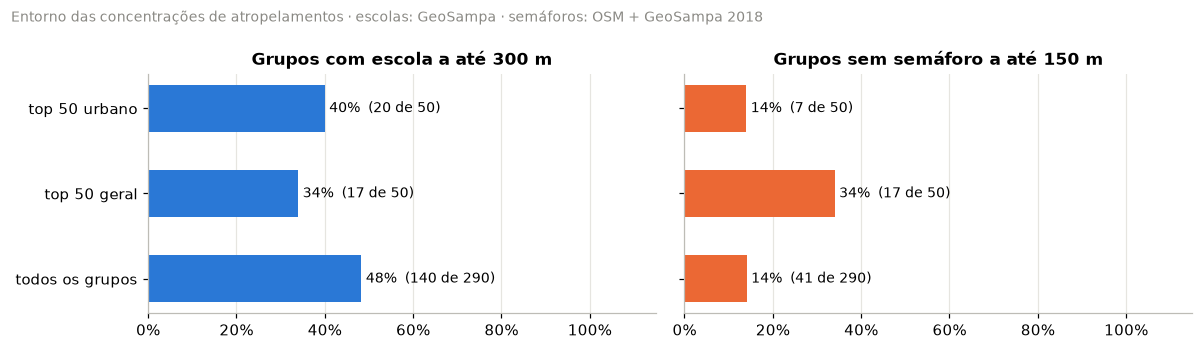

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
y = np.arange(len(resumo))[::-1]
for ax, col, col_n, cor, titulo in [
        (axes[0], "% com escola", "com escola a até 300 m", AZUL, "Grupos com escola a até 300 m"),
        (axes[1], "% sem semáforo", "sem semáforo a até 150 m", LARANJA, "Grupos sem semáforo a até 150 m")]:
    ax.barh(y, resumo[col], color=cor, height=0.55)
    for yi, v, n, tot in zip(y, resumo[col], resumo[col_n], resumo["grupos"]):
        ax.text(v + 1, yi, f"{v:.0f}%  ({int(n)} de {int(tot)})", va="center", fontsize=9)
    ax.set_xlim(0, 115); ax.set_title(titulo, fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y); axes[0].set_yticklabels(resumo.index)
fig.suptitle("Entorno das concentrações de atropelamentos · escolas: GeoSampa · semáforos: OSM + GeoSampa 2018",
             x=0.01, ha="left", fontsize=9, color=CINZA)
fig.tight_layout()
salvar(fig, "04_top50_escolas_semaforos.png")
plt.show()

**Leitura:** o resultado **não** é "os pontos críticos ficam perto de escola".

- **Escolas:** 20 dos 50 primeiros do ranking urbano (40%) têm escola a até 300 m. Entre todos os grupos a
  taxa é **maior** (48%). Isso é esperado, porque a cidade tem ~2,2 mil locais de escola pública e numa área
  densa quase todo ponto tem uma escola por perto. Escola não explica a concentração de atropelamentos. O
  argumento para o modo **"escola"** é **local, ponto a ponto**: em 20 dos 50 pontos mais críticos existe
  entrada e saída de alunos dentro do raio, e é nesses pontos que o modo faz sentido.
- **Conferência com o OSM:** só 12 dos 50 têm escola do OSM a até 300 m, contra 20 pelo GeoSampa, o
  que é coerente com a cobertura menor do OSM (seção 2.3).
- **Semáforos:** 7 dos 50 primeiros (14%) **não têm semáforo em nenhuma das duas bases** a até 150 m. Com uma
  base só, o número mudaria: 10 sem semáforo só pelo OSM e 9 só pelo GeoSampa 2018. É o efeito da cobertura
  incompleta da seção 2.2. Nesses 7 pontos o pedestre atravessa sem controle, e é aí que o modo
  **"pedestre"** (travessia acionada, aviso ao motorista) muda mais a situação. Nos outros 43, o nó atua
  **sobre um semáforo que já existe**, ajustando o tempo de travessia. Isso é mais barato e é o cenário do
  piloto.
- **Travessia semaforizada (OSM):** 21 dos 50 têm um nó de travessia de pedestre com semáforo a até 150 m.
  Os outros têm, no máximo, o semáforo veicular. O pedestre pode estar atravessando sem fase própria, e
  isso precisa ser conferido na verificação manual.
- No top 50 **geral**, 34% ficam sem semáforo porque ali entram as rodovias (BR 381, SP 330). É mais um motivo
  para usar o ranking urbano na decisão.

In [11]:
cols = ["rank_urbano", "rank_prioridade", "via_principal", "n_nao_fatais", "n_fatais", "indice_cet", "n_escolas_300m",
        "distancia_escola_mais_proxima_m", "n_semaforos_150m", "n_travessias_semaforizadas_150m", "n_geosampa_150m"]
alvo = clusters[clusters["rank_urbano"].between(1, 50)]
print("Top 50 urbano: escola a até 300 m E nenhum semáforo a até 150 m em nenhuma das bases")
alvo[(alvo["n_escolas_300m"] > 0) & ~alvo["tem_semaforo"]][cols].round(2)

Top 50 urbano: escola a até 300 m E nenhum semáforo a até 150 m em nenhuma das bases


,rank_urbano,rank_prioridade,via_principal,n_nao_fatais,n_fatais,indice_cet,n_escolas_300m,distancia_escola_mais_proxima_m,n_semaforos_150m,n_travessias_semaforizadas_150m,n_geosampa_150m
22,10.0,23,RUA DEMAS ZITTO,5,1,6.68,5,97.5,0,0,0
56,42.0,57,AVENIDA JACUPESSEGO,8,1,11.48,1,227.6,0,0,0
58,44.0,59,ESTRADA CANAL DE COCAIA,4,2,11.67,5,31.3,0,0,0
61,47.0,62,RUA ANTONIO DE FRANCA E SILVA,3,2,11.91,1,254.5,0,0,0


**Leitura:** quatro pontos do top 50 urbano juntam **escola por perto e nenhum semáforo em nenhuma das bases**:
Rua Demas Zitto (10º, 5 escolas, a mais próxima a ~100 m), Av. Jacu Pêssego (42º), Estrada Canal de Cocaia
(44º, 5 escolas, a ~30 m) e Rua Antônio de França e Silva (47º). Na versão só com o GeoSampa havia um quinto
ponto, a Estrada do Campo Limpo, mas o OSM mostra semáforo ali. Todos ficam na **periferia**: zona sul
(Grajaú) e zona leste. **Demas Zitto e Canal de Cocaia ficam a ~250 m um do outro, no Grajaú**, e formam na
prática um único foco, com 5 escolas a até 300 m de cada um e nenhum semáforo. É o candidato mais forte a
uma **segunda fase** com o modo escola de verdade, e mostra que o projeto não se limita ao Centro.

*Ressalva da conferência:* o OSM **não tem nenhuma escola** em volta de Demas Zitto e Canal de Cocaia, contra
5 do GeoSampa. Pelo resultado da seção 2.3, isso indica falta de mapeamento no OSM no Grajaú, e não ausência
de escolas. Mesmo assim, antes de levar esse foco para o PDF como "zona escolar", vale conferir as escolas
pelo nome no Street View ou no site da Secretaria de Educação.

## 5. O piloto: Largo da Concórdia e Av. Celso Garcia

Os grupos do piloto são os que têm atropelamentos registrados na Av. Celso Garcia ou no Largo da Concórdia
(campo `logradouro` da tabela `sinistros`). Para cada um, listamos as escolas a até 300 m **pelo nome**, os
nós de semáforo e travessia do OSM (com a data da última edição) e os semáforos do cadastro de 2018.

In [12]:
PILOTO_VIAS = ["AVENIDA CELSO GARCIA", "LARGO DA CONCORDIA"]
ids_piloto = sin.loc[sin["via"].isin(PILOTO_VIAS), "cluster_id"].unique()
ids_largo = sin.loc[sin["via"].eq("LARGO DA CONCORDIA"), "cluster_id"].unique()
piloto = clusters[clusters["cluster_id"].isin(ids_piloto)].sort_values("rank_prioridade")
piloto[["cluster_id", "rank_urbano", "rank_prioridade", "vias", "n_nao_fatais", "n_fatais", "indice_cet",
        "n_escolas_300m", "n_escolas_osm_300m", "distancia_escola_mais_proxima_m", "n_semaforos_150m",
        "n_travessias_semaforizadas_150m", "n_geosampa_150m", "fonte_semaforo"]].round(1)

,cluster_id,rank_urbano,rank_prioridade,vias,n_nao_fatais,n_fatais,indice_cet,n_escolas_300m,n_escolas_osm_300m,distancia_escola_mais_proxima_m,n_semaforos_150m,n_travessias_semaforizadas_150m,n_geosampa_150m,fonte_semaforo
40,139,26.0,41,AVENIDA RANGEL PESTANA | LARGO DA CONCORDIA | ...,51,2,10.4,0,0,337.1,6,2,4,ambas
109,29,94.0,110,AVENIDA CELSO GARCIA | RUA BRESSER | RUA JOSE ...,34,2,15.0,0,1,456.1,2,0,3,ambas
130,248,115.0,131,AVENIDA CELSO GARCIA | RUA CESARIO ALVIM,8,0,15.8,0,0,454.9,1,0,1,ambas
202,223,186.0,203,AVENIDA CELSO GARCIA,9,0,19.1,0,0,355.7,2,0,2,ambas
204,183,188.0,205,AVENIDA CELSO GARCIA | RUA MARIA MARCOLINA | R...,6,2,19.1,2,2,186.5,3,2,2,ambas


In [13]:
def listar(tab, c, raio, rotulo, fmt):
    i, d = BallTree(rad(tab), metric="haversine").query_radius(c, r=raio / R_TERRA, return_distance=True)
    # BallTree devolve posições, não rótulos do índice
    s = tab.iloc[i[0]].assign(dist_m=(d[0] * R_TERRA).round()).sort_values("dist_m")
    print(f"  {rotulo}: {len(s)}")
    for _, r in s.iterrows():
        print(f"     - {r.dist_m:>4.0f} m · {fmt(r)}")

def detalhe(cid: int):
    g = clusters.loc[clusters["cluster_id"].eq(cid)].iloc[0]
    c = np.radians([[g.lat_centro, g.lon_centro]])
    ru = "fora" if pd.isna(g.rank_urbano) else int(g.rank_urbano)
    print(f"■ cluster {cid} | rank urbano {ru} | rank geral {g.rank_prioridade} | {g.vias}")
    print(f"  {g.n_nao_fatais} não fatais, {g.n_fatais} fatais, extensão {g.extensao_m:.0f} m, índice {g.indice_cet:.2f}"
          f" | fonte_semaforo = {g.fonte_semaforo}")
    if g.n_escolas_300m == 0:
        print(f"  GeoSampa · escolas a até 300 m: 0 (a mais próxima está a {g.distancia_escola_mais_proxima_m:.0f} m: "
              f"{g.escola_mais_proxima})")
    else:
        listar(escolas, c, 300, "GeoSampa · escolas a até 300 m", lambda r: f"{r.tipos} {r.nomes} ({r.redes.lower()})")
    # conferência: as bases discordam? (uma tem escola no raio e a outra não, ou contagens diferentes)
    if (g.n_escolas_300m > 0) != (g.n_escolas_osm_300m > 0) or g.n_escolas_300m != g.n_escolas_osm_300m:
        print("  ⚠ GeoSampa e OSM discordam neste raio; escolas do OSM:")
    listar(esc_osm, c, 300, "OSM · escolas (amenity=school) a até 300 m",
           lambda r: f"{r['name'] or '(sem nome)'} [{r.osm_type} {r.osm_id}, editado {pd.to_datetime(r.timestamp):%m/%Y}]")
    listar(osm_sem, c, 150, "OSM · nós de semáforo a até 150 m",
           lambda r: f"node {r.osm_id} (editado em {r.ultima_edicao:%m/%Y})" + (" + travessia" if r.e_travessia else ""))
    listar(osm_trav[~osm_trav["e_semaforo"]], c, 150, "OSM · nós só de travessia semaforizada a até 150 m",
           lambda r: f"node {r.osm_id} (editado em {r.ultima_edicao:%m/%Y})")
    listar(gs_comum, c, 150, "GeoSampa 2018 · semáforos comuns a até 150 m", lambda r: r.nm_endereco)
    print()

for cid in piloto["cluster_id"]:
    detalhe(cid)

■ cluster 139 | rank urbano 26 | rank geral 41 | AVENIDA RANGEL PESTANA | LARGO DA CONCORDIA | RUA BARAO DE LADARIO
  51 não fatais, 2 fatais, extensão 591 m, índice 10.37 | fonte_semaforo = ambas
  GeoSampa · escolas a até 300 m: 0 (a mais próxima está a 337 m: EE ANCHIETA PADRE)
  OSM · escolas (amenity=school) a até 300 m: 0
  OSM · nós de semáforo a até 150 m: 6
     -   66 m · node 2449978346 (editado em 04/2021)
     -   78 m · node 437564182 (editado em 06/2021)
     -   80 m · node 155430748 (editado em 07/2021)
     -  109 m · node 434003360 (editado em 11/2023)
     -  125 m · node 5639817289 (editado em 07/2021)
     -  140 m · node 437564134 (editado em 07/2021)
  OSM · nós só de travessia semaforizada a até 150 m: 2
     -  121 m · node 4736955204 (editado em 04/2026)
     -  128 m · node 434003356 (editado em 04/2026)
  GeoSampa 2018 · semáforos comuns a até 150 m: 4
     -   65 m · CONCORDIA, LG DA x MILLER, R x FIRMINO WHITAKER, R MIN
     -   72 m · RANGEL PESTANA, AV 

  OSM · nós de semáforo a até 150 m: 3
     -   78 m · node 177474390 (editado em 06/2025)
     -  114 m · node 5268233505 (editado em 12/2017)
     -  138 m · node 130112042 (editado em 12/2017)
  OSM · nós só de travessia semaforizada a até 150 m: 2
     -   58 m · node 2530563697 (editado em 05/2021)
     -   61 m · node 2530563702 (editado em 05/2021)
  GeoSampa 2018 · semáforos comuns a até 150 m: 2
     -   82 m · CELSO GARCIA, AV x ELIAS, R STO x ANGELO VITA, R DR - (C104)
     -  131 m · CELSO GARCIA, AV x FELIPPE, R S x VILELA, R



**Leitura: o piloto no Largo da Concórdia se confirma?**

**Sim, como ponto crítico de pedestres e como local para o nó atuar sobre o semáforo. Não, como zona escolar.**

- **Gravidade:** o grupo do Largo da Concórdia (cluster 139) é o **26º de 273 no ranking urbano (top 10%)**,
  com 51 não fatais e 2 fatais, e tem o **4º maior volume ponderado da cidade** (notebook 03).
- **Semáforos, confirmados pelas duas bases** (`fonte_semaforo = ambas`): o cadastro de 2018 tem **4
  cruzamentos semaforizados a até 150 m** (Largo × R. Miller/R. Firmino Whitaker, Rangel Pestana × R.
  Joaquim Nabuco, Largo × Viaduto do Gasômetro/R. Barão de Ladário, Rangel Pestana × R. Gomes Cardim). O OSM
  tem **6 nós de semáforo e 2 nós de travessia semaforizada**. Os dois nós de travessia foram editados em
  **abril de 2026**, ou seja, alguém conferiu o local há poucos meses. O nó tem onde atuar: o modo
  **"pedestre"** (tempo de travessia maior para idosos, fase acionada, aviso na placa) usa a infraestrutura
  que já existe. O dado do notebook 01 de que **idosos são 46,6% das mortes** reforça o ajuste de tempo
  nesse ponto, que tem muito fluxo de pedestres (estação Brás, comércio, corredor de ônibus).
- **Escolas:** **nenhuma escola a até 300 m, e as duas bases concordam**: GeoSampa 0 e OSM 0. Pelo OSM,
  isso inclui as particulares. A mais próxima no GeoSampa é a EE Padre Anchieta, a ~340 m em linha reta do
  centro do grupo, logo fora do raio. Na própria Celso Garcia, só o trecho da R. Santo
  Elias / R. Maria Marcolina (cluster 183, 188º urbano) tem escolas por perto: a EE Profª Benedita Ribas e a
  EMEI Pres. Dutra, a ~190 m.

**Decisão (prevista no planejamento):** o piloto fica no **Largo da Concórdia**, com os modos "normal",
"pedestre", "chuva" e "ambulância" baseados em dados. O **modo "escola" entra como cenário de
demonstração**, identificado como tal no vídeo e no PDF. O foco Demas Zitto / Canal de Cocaia (seção 4) mostra
onde ele teria aplicação real.

*Ressalva:* nenhuma das bases diz se os semáforos do Largo têm **foco para pedestre** ou **contagem
regressiva**. Isso vai para a verificação manual (seção 5.2), em que o Largo é a última linha da planilha.

### 5.1 Mapa estático do piloto (para o PDF)

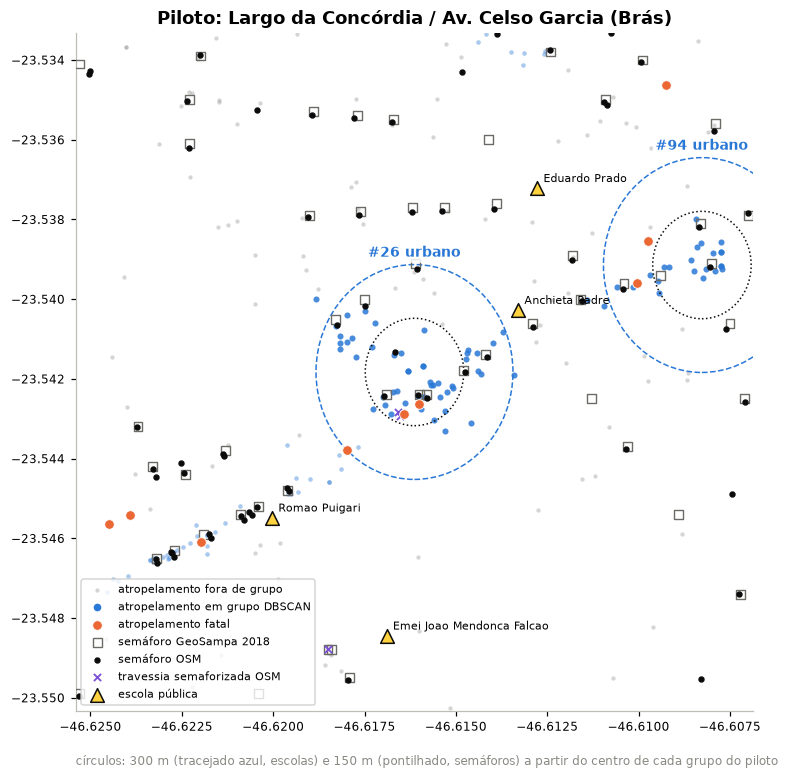

In [14]:
foco = piloto.iloc[0]  # grupo do piloto mais bem colocado = centro do mapa
lat0, lon0 = foco.lat_centro, foco.lon_centro
JAN = 0.0085  # ~950 m para cada lado
with sqlite3.connect(DB_PATH) as con:
    pts = pd.read_sql_query(f"""SELECT latitude, longitude, fatal, cluster_id FROM sinistros
                                WHERE latitude BETWEEN {lat0 - JAN} AND {lat0 + JAN}
                                  AND longitude BETWEEN {lon0 - JAN} AND {lon0 + JAN}""", con)
k = 1 / np.cos(np.radians(lat0))
na_janela = lambda d: d[d["latitude"].between(lat0 - JAN, lat0 + JAN) & d["longitude"].between(lon0 - JAN * k, lon0 + JAN * k)]

fig, ax = plt.subplots(figsize=(8, 8))
fora = pts[pts["cluster_id"].isna()]
ax.scatter(fora["longitude"], fora["latitude"], s=8, color=CINZA, alpha=0.35, linewidths=0, label="atropelamento fora de grupo")
for cid, d in pts.dropna(subset=["cluster_id"]).groupby("cluster_id"):
    pil = cid in set(piloto["cluster_id"])
    ax.scatter(d["longitude"], d["latitude"], s=16 if pil else 9, color=AZUL, alpha=0.85 if pil else 0.4, linewidths=0)
ax.scatter([], [], color=AZUL, s=16, label="atropelamento em grupo DBSCAN")
f = pts[pts["fatal"] == 1]
ax.scatter(f["longitude"], f["latitude"], s=40, color=LARANJA, edgecolors="white", linewidths=0.6, label="atropelamento fatal", zorder=4)
s = na_janela(gs_comum)
ax.scatter(s["longitude"], s["latitude"], marker="s", s=34, facecolors="none", edgecolors="#6b6a65", linewidths=0.9,
           label="semáforo GeoSampa 2018", zorder=3)
s = na_janela(osm_sem)
ax.scatter(s["longitude"], s["latitude"], marker="o", s=10, color="#0b0b0b", label="semáforo OSM", zorder=3)
s = na_janela(osm_trav)
ax.scatter(s["longitude"], s["latitude"], marker="x", s=22, color="#7b4fd6", linewidths=1.2, label="travessia semaforizada OSM", zorder=3)
e = na_janela(escolas)
ax.scatter(e["longitude"], e["latitude"], marker="^", s=80, color="#ffd23f", edgecolors="#0b0b0b", label="escola pública", zorder=5)
for _, r in e.iterrows():
    ax.annotate(r.nomes.title()[:28], (r.longitude, r.latitude), fontsize=7, xytext=(4, 4), textcoords="offset points")
for _, g in piloto.iterrows():
    ax.add_patch(plt.Circle((g.lon_centro, g.lat_centro), 300 / 111_320, fill=False, ls="--", ec=AZUL, lw=1))
    ax.add_patch(plt.Circle((g.lon_centro, g.lat_centro), 150 / 111_320, fill=False, ls=":", ec="#0b0b0b", lw=1))
    ru = "—" if pd.isna(g.rank_urbano) else int(g.rank_urbano)
    ax.annotate(f"#{ru} urbano", (g.lon_centro, g.lat_centro + 300 / 111_320), fontsize=9, fontweight="bold",
                color=AZUL, ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_xlim(lon0 - JAN * k, lon0 + JAN * k); ax.set_ylim(lat0 - JAN, lat0 + JAN)
ax.set_aspect(k); ax.grid(False); ax.tick_params(labelsize=8)
ax.set_title("Piloto: Largo da Concórdia / Av. Celso Garcia (Brás)")
ax.legend(loc="lower left", fontsize=7.5, frameon=True)
ax.text(0, -0.08, "círculos: 300 m (tracejado azul, escolas) e 150 m (pontilhado, semáforos) a partir do centro de cada grupo do piloto",
        transform=ax.transAxes, fontsize=8, color=CINZA)
salvar(fig, "04_piloto_entorno.png")
plt.show()

### 5.2 Planilha para verificação manual (Street View)

Nenhuma das duas bases responde as perguntas que mais importam para o pedestre idoso: **o semáforo tem
foco para o pedestre? Tem contagem regressiva?** A verificação é feita à mão, no Street View, para os **10
primeiros do ranking urbano** e para o(s) grupo(s) do **Largo da Concórdia**.

Arquivo: `docs/evidencias/estudo_b/verificacao_manual.csv`. O link abre o Street View no centróide do grupo
(o Google leva à imagem mais próxima). As três últimas colunas ficam **vazias** para preenchimento manual:
`tem_semaforo_pedestre` e `tem_contagem_regressiva` (sim / não / não dá para ver) e `data_imagem` (a data
que o Street View mostra no canto da imagem). A coluna `via_principal` foi acrescentada só para facilitar a
identificação do ponto. `rank` é a posição no **ranking urbano**.

Se o arquivo já existir e tiver algo preenchido, ele **não é sobrescrito**.

In [15]:
ARQ_VERIF = EVID / "verificacao_manual.csv"
vm = (pd.concat([clusters[clusters["rank_urbano"].between(1, 10)], clusters[clusters["cluster_id"].isin(ids_largo)]])
        .drop_duplicates("cluster_id").sort_values("rank_urbano"))
vm = pd.DataFrame({
    "cluster_id": vm["cluster_id"].astype(int), "rank": vm["rank_urbano"].astype(int), "via_principal": vm["via_principal"],
    "lat": vm["lat_centro"].round(6), "lon": vm["lon_centro"].round(6),
    "link_street_view": [f"https://www.google.com/maps/@?api=1&map_action=pano&viewpoint={la:.6f},{lo:.6f}"
                         for la, lo in zip(vm["lat_centro"], vm["lon_centro"])],
    "tem_semaforo_pedestre": "", "tem_contagem_regressiva": "", "data_imagem": ""})
preenchido = False
if ARQ_VERIF.exists():
    antigo = pd.read_csv(ARQ_VERIF, sep=";", dtype=str, keep_default_na=False)
    preenchido = antigo[["tem_semaforo_pedestre", "tem_contagem_regressiva", "data_imagem"]].ne("").any().any()
if preenchido:
    print(f"{ARQ_VERIF.name} já tem preenchimento manual: mantido sem alteração")
else:
    vm.to_csv(ARQ_VERIF, sep=";", index=False, encoding="utf-8-sig")
    print(f"salvo: {ARQ_VERIF.relative_to(ROOT)} ({len(vm)} grupos)")
vm

salvo: docs\evidencias\estudo_b\verificacao_manual.csv (11 grupos)


,cluster_id,rank,via_principal,lat,lon,link_street_view,tem_semaforo_pedestre,tem_contagem_regressiva,data_imagem
12,48,1,AVENIDA DO IMPERADOR,-23.513499,-46.443804,https://www.google.com/maps/@?api=1&map_action...,,,
13,267,2,AVENIDA BRAZ LEME,-23.503738,-46.636482,https://www.google.com/maps/@?api=1&map_action...,,,
15,225,3,AVENIDA DO ESTADO,-23.562770,-46.612324,https://www.google.com/maps/@?api=1&map_action...,,,
16,212,4,ESTRADA DO M'BOI MIRIM,-23.722031,-46.785142,https://www.google.com/maps/@?api=1&map_action...,,,
17,163,5,AVENIDA DONA BELMIRA MARIN,-23.746691,-46.688109,https://www.google.com/maps/@?api=1&map_action...,,,
18,32,6,ACESSO ESTRADA DO M BOI MIRIM,-23.672476,-46.743043,https://www.google.com/maps/@?api=1&map_action...,,,
19,87,7,AVENIDA JACUPESSEGO,-23.531941,-46.456018,https://www.google.com/maps/@?api=1&map_action...,,,
20,284,8,AVENIDA LUIZ GUSHIKEN,-23.667987,-46.737702,https://www.google.com/maps/@?api=1&map_action...,,,
21,120,9,AVENIDA JOSE PINHEIRO BORGES,-23.539252,-46.469763,https://www.google.com/maps/@?api=1&map_action...,,,
22,56,10,RUA DEMAS ZITTO,-23.744618,-46.670437,https://www.google.com/maps/@?api=1&map_action...,,,


## 6. Alagamento

> **PENDENTE: pontos de alagamento do CGE.** O CGE (Centro de Gerenciamento de Emergências) não publica os
> pontos de alagamento em formato aberto (CSV ou camada no GeoSampa): eles aparecem só no mapa em tempo real e
> nos boletins. Por isso esta base **não foi montada agora**. Há dois caminhos para ela entrar no projeto:
>
> 1. **Trabalho futuro:** pedir a série histórica ao CGE (Lei de Acesso à Informação) e cruzar com os grupos,
>    da mesma forma que as escolas (distância ao ponto de alagamento mais próximo e ocorrências por ano).
> 2. **Base simulada para a demonstração do modo "chuva":** alguns pontos marcados à mão a partir dos boletins
>    públicos, gravados na tabela `pontos_alagamento` (prevista em `src/central/schema.sql`) com `fonte`
>    identificando claramente que é **simulado/parcial**, para não passar como dado oficial.
>
> Até lá, o modo "chuva" do nó depende só da previsão de chuva (Open-Meteo), e não do histórico de
> alagamento no ponto.

## 7. Mapa interativo com o entorno

Novo mapa em `docs/evidencias/estudo_b/mapa_entorno.html`. O mapa do notebook 03 continua como está. As
camadas ligam e desligam no controle do canto superior direito:

- **Top 50 urbano**: círculos com raio proporcional ao peso e cor por presença de escola e semáforo;
- **Escolas públicas** (GeoSampa), **Escolas OSM** (conferência, desligada), **Semáforos OSM**, **Travessias com semáforo OSM** e **Semáforos GeoSampa 2018**
  (comuns em cinza, piscantes em amarelo): só os pontos a até 600 m de algum grupo do top 50 urbano. A
  cidade inteira passaria de 18 mil pontos, o arquivo ficaria pesado e o mapa ilegível;
- **Raios do piloto**: 300 m e 150 m em volta dos grupos do piloto.

In [16]:
top50 = clusters[clusters["rank_urbano"].between(1, 50)].copy()
arv_top = BallTree(rad(top50, "lat_centro", "lon_centro"), metric="haversine")
perto = lambda d: d[arv_top.query(rad(d), k=1)[0][:, 0] * R_TERRA <= 600]

def cor(g):
    if g.n_escolas_300m > 0 and not g.tem_semaforo: return "#b3261e"
    if not g.tem_semaforo: return LARANJA
    if g.n_escolas_300m > 0: return "#7b4fd6"
    return AZUL

mapa = folium.Map(location=[-23.58, -46.62], zoom_start=11, tiles="OpenStreetMap")
camadas = {}
def camada(nome, show=True):
    camadas[nome] = folium.FeatureGroup(name=nome, show=show)
    return camadas[nome]

c = camada("Top 50 urbano (pontos críticos)")
for _, g in top50.iloc[::-1].iterrows():
    popup = (f"<b>#{int(g.rank_urbano)} urbano · {g.via_principal.title()}</b><br>{g.vias.title()}<br>"
             f"fatais: {g.n_fatais} · não fatais: {g.n_nao_fatais} · índice: {g.indice_cet:.2f}<br>"
             f"escolas ≤ 300 m: {g.n_escolas_300m} (mais próxima: {g.distancia_escola_mais_proxima_m:.0f} m)<br>"
             f"{g.escolas_300m.title() if g.escolas_300m else ''}<br>"
             f"OSM ≤ 150 m: {g.n_semaforos_150m} nós de semáforo, {g.n_travessias_semaforizadas_150m} de travessia<br>"
             f"GeoSampa 2018 ≤ 150 m: {g.n_geosampa_150m} · fonte: {g.fonte_semaforo or 'nenhuma'}")
    folium.CircleMarker([g.lat_centro, g.lon_centro], radius=4 + 1.6 * np.sqrt(g.peso), color=cor(g), weight=2,
                        fill=True, fill_opacity=0.55, popup=folium.Popup(popup, max_width=380),
                        tooltip=f"#{int(g.rank_urbano)} {g.via_principal.title()}").add_to(c)

d = perto(escolas); c = camada(f"Escolas públicas ({len(d)})")
for _, r in d.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=4.5, color="#0b0b0b", weight=1, fill=True, fill_color="#ffd23f",
                        fill_opacity=1, tooltip=f"{r.tipos} {r.nomes.title()} ({r.redes.lower()})").add_to(c)
d = perto(esc_osm); c = camada(f"Escolas OSM, conferência ({len(d)})", show=False)
for _, r in d.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=4, color="#d4a900", weight=1.5, fill=True, fill_color="white",
                        fill_opacity=1, tooltip=f"OSM escola · {r['name'] or '(sem nome)'}").add_to(c)
d = perto(osm_sem); c = camada(f"Semáforos OSM ({len(d)} nós)", show=False)
for _, r in d.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=2.5, color="#0b0b0b", weight=1, fill=True, fill_color="#0b0b0b",
                        fill_opacity=0.9, tooltip=f"OSM semáforo · node {r.osm_id} · editado {r.ultima_edicao:%m/%Y}").add_to(c)
d = perto(osm_trav); c = camada(f"Travessias com semáforo OSM ({len(d)} nós)", show=False)
for _, r in d.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=3, color="#7b4fd6", weight=1.5, fill=True, fill_color="white",
                        fill_opacity=1, tooltip=f"OSM travessia semaforizada · node {r.osm_id} · editado {r.ultima_edicao:%m/%Y}").add_to(c)
d1, d2 = perto(gs_comum), perto(gs_pisc); c = camada(f"Semáforos GeoSampa 2018 ({len(d1)} + {len(d2)} piscantes)", show=False)
for d, cor_p, tipo in [(d1, "#6b6a65", "comum"), (d2, "#f2c200", "piscante")]:
    for _, r in d.iterrows():
        folium.RegularPolygonMarker([r.latitude, r.longitude], number_of_sides=4, radius=4, color=cor_p, weight=1.5,
                                    fill=False, tooltip=f"GeoSampa 2018 ({tipo}) · {r.nm_endereco}").add_to(c)
c = camada("Piloto: raios de 300 m (escolas) e 150 m (semáforos)")
for _, g in piloto.iterrows():
    folium.Circle([g.lat_centro, g.lon_centro], radius=300, color=AZUL, weight=1.5, dash_array="6", fill=False).add_to(c)
    folium.Circle([g.lat_centro, g.lon_centro], radius=150, color="#0b0b0b", weight=1, dash_array="2", fill=False).add_to(c)
for c in camadas.values():
    c.add_to(mapa)
legenda = """<div style="position: fixed; bottom: 24px; left: 12px; z-index: 9999; background: white; padding: 8px 10px;
 border: 1px solid #bbb; border-radius: 6px; font: 12px sans-serif; line-height: 1.5">
 <b>Cor dos pontos críticos</b><br>
 <span style="color:#b3261e">●</span> escola ≤ 300 m e sem semáforo ≤ 150 m<br>
 <span style="color:#eb6834">●</span> sem semáforo ≤ 150 m<br>
 <span style="color:#7b4fd6">●</span> escola ≤ 300 m, com semáforo<br>
 <span style="color:#2a78d6">●</span> com semáforo, sem escola<br>
 <span style="color:#d4a900">●</span> escola pública · ● semáforo OSM · ○ travessia OSM · □ GeoSampa 2018</div>"""
mapa.get_root().html.add_child(folium.Element(legenda))
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(EVID / "mapa_entorno.html")
print(f"salvo: {(EVID / 'mapa_entorno.html').relative_to(ROOT)} | camadas: {list(camadas)}")
# O mapa não é exibido aqui para o notebook não carregar ~2 MB de HTML; abra o arquivo salvo no navegador.

salvo: docs\evidencias\estudo_b\mapa_entorno.html | camadas: ['Top 50 urbano (pontos críticos)', 'Escolas públicas (125)', 'Escolas OSM, conferência (98)', 'Semáforos OSM (806 nós)', 'Travessias com semáforo OSM (509 nós)', 'Semáforos GeoSampa 2018 (645 + 48 piscantes)', 'Piloto: raios de 300 m (escolas) e 150 m (semáforos)']


## 8. Checagem final no banco

In [17]:
with sqlite3.connect(DB_PATH) as con:
    display(pd.read_sql_query("""
        SELECT rank_urbano, via_principal, n_fatais, n_nao_fatais, ROUND(indice_cet, 2) AS indice_cet, n_escolas_300m,
               n_escolas_osm_300m,
               ROUND(distancia_escola_mais_proxima_m) AS dist_escola_m, n_semaforos_150m, n_travessias_semaforizadas_150m,
               tem_semaforo, fonte_semaforo
        FROM clusters WHERE rank_urbano IS NOT NULL ORDER BY rank_urbano LIMIT 10""", con))
    display(pd.read_sql_query("""
        SELECT COUNT(*) AS grupos, SUM(n_escolas_300m > 0) AS com_escola_300m, SUM(tem_semaforo = 0) AS sem_semaforo_150m,
               SUM(fonte_semaforo = 'ambas') AS ambas, SUM(fonte_semaforo = 'osm') AS so_osm,
               SUM(fonte_semaforo = 'geosampa_2018') AS so_geosampa
        FROM clusters""", con))

,rank_urbano,via_principal,n_fatais,n_nao_fatais,indice_cet,n_escolas_300m,n_escolas_osm_300m,dist_escola_m,n_semaforos_150m,n_travessias_semaforizadas_150m,tem_semaforo,fonte_semaforo
0,1,AVENIDA DO IMPERADOR,1,13,3.12,0,0,321.0,2,0,1,ambas
1,2,AVENIDA BRAZ LEME,2,2,3.75,0,0,423.0,4,3,1,ambas
2,3,AVENIDA DO ESTADO,2,14,4.24,0,0,371.0,3,2,1,ambas
3,4,ESTRADA DO M'BOI MIRIM,1,27,4.34,0,0,797.0,2,0,1,ambas
4,5,AVENIDA DONA BELMIRA MARIN,1,5,4.54,0,0,376.0,0,0,1,geosampa_2018
5,6,ACESSO ESTRADA DO M BOI MIRIM,3,63,5.44,0,1,385.0,8,4,1,ambas
6,7,AVENIDA JACUPESSEGO,2,7,5.63,0,0,370.0,0,0,0,NaN
7,8,AVENIDA LUIZ GUSHIKEN,2,2,5.96,0,2,332.0,2,7,1,ambas
8,9,AVENIDA JOSE PINHEIRO BORGES,2,17,6.11,1,0,182.0,0,2,1,ambas
9,10,RUA DEMAS ZITTO,1,5,6.68,5,0,98.0,0,0,0,NaN


,grupos,com_escola_300m,sem_semaforo_150m,ambas,so_osm,so_geosampa
0,290,140,41,205,12,32


## 9. Limitações

- **As fontes têm defeitos diferentes** (seção 2): o OSM é recente, mas voluntário e desigual entre bairros; o
  GeoSampa é oficial, mas de 2018. Usar as duas (`tem_semaforo` = alguma delas) reduz o risco de marcar "sem
  semáforo" por falha de cadastro, mas um semáforo ausente nas duas bases continua invisível.
- **Nenhuma base diz se há foco para pedestre, contagem regressiva ou botoeira** (as marcações do OSM existem,
  mas quase ninguém preenche). `tem_semaforo` significa "há controle semafórico", não "a travessia é segura".
  A planilha de verificação manual (seção 5.2) cobre o top 10 e o piloto.
- **Escolas sem data.** A data de atualização das camadas do GeoSampa não é informada pela fonte, e o
  Catálogo de Escolas do INEP não pôde ser baixado (duas tentativas; o portal derrubou a conexão). Escolas
  abertas ou fechadas recentemente podem estar erradas. O OSM serve de conferência (seção 2.3), mas também é
  incompleto e mistura escolas públicas e particulares.
- **Distância em linha reta.** 300 m em linha reta pode ser bem mais a pé, se houver rio, linha de trem ou
  viaduto no meio. No Brás, a linha da CPTM/Metrô corta a região.
- **O raio parte do centróide.** Em grupos longos (~600 m), uma escola no fim do trecho pode ficar fora dos
  300 m, e o círculo de 150 m não cobre todo o trecho.
- **Contagens do OSM são de nós, não de cruzamentos** (seção 2.1). Use para "tem ou não tem", não para comparar
  quantidades entre grupos.
- **Escolas privadas e creches fora do indicador** (decisão da seção 2.1).
- **Alagamento pendente** (seção 6).